# Параметры

In [1]:
from gte.config import parameters as gtep

ModuleNotFoundError: No module named 'gte'

In [ ]:
for k, v in gtep.items():
    print(f"{k:<15}: {v}")

rf             : rotation_frequency
l              : thermal_conductivity
hc             : heat_capacity
hcp            : heat_capacity_pressure
hcv            : heat_capacity_volume
k              : adiabatic_index
gc             : gas_const
eo             : excess_oxidizing
T              : static_temperature
P              : static_pressure
D              : staticdensity
TT             : total_temperature
PP             : total_pressure
DD             : total_density
m              : mass
v              : volume
ss             : sound_speed
ss_critical    : critical_sound_speed
c              : absolute_velocity
u              : portable_velocity
w              : relative_velocity
pipi           : total_pressure_ratio
pi             : static_pressure_ratio
titi           : total_temperature_ratio
ti             : static_temperature_ratio
mach           : mach_number
Nu             : nusselt_number
efficiency     : efficiency
effeff         : total_efficiency
eff_burn       : efficie

In [ ]:
from thermodynamics import atmosphere_standard, gas_const, heat_capacity_p, stoichiometry, lower_heat, gas_const_exhaust_fuel
from thermodynamics import T0
from substance import Substance

In [ ]:
air = Substance(
    "air",
    composition={"N2": 0.78, "O2": 0.21, "Ar": 0.009, "CO2": 0.0004},
    parameters={
        gtep.m: 50.0,
        gtep.gc: 287.14,
        gtep.TT: 300.0,
        gtep.PP: 101325.0,
        gtep.hcp: 1006.0,
        gtep.k: 1.4,
        gtep.c: 0.0,
    },
    functions={
        gtep.gc: lambda temperature: gas_const("air"),
        gtep.hcp: lambda temperature: heat_capacity_p("air", temperature),
    },
)

fuel = Substance(
    "kerosene",
    composition={"C": 0.85, "H": 0.15},
    parameters={
        gtep.m: 3,
        gtep.TT: 40 + T0,
        gtep.PP: 101_325,
        "stoichiometry": stoichiometry("kerosene"),
        "lower_heat": lower_heat("kerosene"),
    },
    functions={
        gtep.gc: lambda excess_oxidizing: gas_const_exhaust_fuel(excess_oxidizing, fuel="kerosene"),
        gtep.hcp: lambda temperature: 200,
    },
)

In [ ]:
from gte.nodes.compressor import Compressor
from gte.nodes.combustion_chamber import CombustionChamber
from gte.nodes.turbine import Turbine
from gte.nodes.nozzle import Nozzle

In [ ]:
compressor = Compressor({}, "АЛ-41Ф")

In [ ]:
compressor.variables

('total_efficiency', 'total_pressure_ratio', 'power')

In [ ]:
compressor.parameters["total_pressure_ratio"] = 6

In [ ]:
compressor.is_solvable

False

In [ ]:
compressor.parameters["total_efficiency"] = 0.85

In [ ]:
compressor.is_solvable

True

In [ ]:
outlet, parameters = compressor.calculate(air, parameters=compressor.parameters)

In [ ]:
for parameter, value in outlet.parameters.items():
    print(f"{parameter:<25}: {value}")

mass                     : 50.0
total_temperature        : 532.2979315327493
total_pressure           : 607950.0
gas_const                : 287.14
heat_capacity_pressure   : 1037.2558324484967
total_density            : 3.9775842583793817
adiabatic_index          : 1.3827942133453304
critical_sound_speed     : 421.18679181026033


In [ ]:
parameters

{'total_efficiency': 0.85,
 'total_pressure_ratio': 6,
 'power': 11816242.700103628}

In [ ]:
compressor.validate(air, outlet)

{}

In [ ]:
compressor.check_real(air, outlet)

''

In [ ]:
help(compressor._equations)

Help on method _equations in module gte.nodes.compressor.compressor:

_equations(x: Tuple[float], args: Dict[str, Any]) -> Tuple[float, float, float] class method of gte.nodes.compressor.compressor.Compressor
    power = m * hcp * (T*_outlet - T*_inlet)
    T*_outlet = T*_inlet * (1 + (pi* ** ((k-1) / k) - 1) / eff*)
    pi* = P*_outlet / P*_inlet



In [ ]:
cc = CombustionChamber({}, "КС")

In [ ]:
cc.variables

('efficiency_burn', 'total_pressure_ratio')

In [ ]:
cc.efficiency_burn = 0.99

In [ ]:
cc.is_solvable(air, kerosene)

'count_variables=1 + count_outlet_variables=2 > count_equations=2'

In [ ]:
cc.pressure_efficiency = 0.95

In [ ]:
cc.is_solvable(air, kerosene)

''

In [ ]:
outlet = cc.solve(air, kerosene)

In [ ]:
for parameter, value in cc.summary.items():
    print(f"{parameter:<30}: {value}")

name                          : КС
inlet_mass_flow               : 50.0
inlet_gas_const               : 287.14
inlet_total_temperature       : 300.0
inlet_total_pressure          : 101325.0
inlet_heat_capacity_pressure  : 1006.0
inlet_adiabatic_index         : 1.4
inlet_absolute_velocity       : 0.0
inlet_enthalpy                : 11883.658364440029
outlet_mass_flow              : 53.0
outlet_excess_oxidizing       : 1.1407711613050424
outlet_total_temperature      : 2351.0476377213786
outlet_total_pressure         : 96258.75143436715
outlet_gas_const              : 288.801771908408
outlet_heat_capacity_pressure : 1286.503463000145
outlet_total_density          : 0.14176823800305463
outlet_adiabatic_index        : 1.289467056623294
outlet_critical_sound_speed   : 874.5478275537812
leak                          : 0
efficiency_burn               : 0.99
pressure_efficiency           : 0.95
fuel_mass_flow                : 3
fuel_total_temperature        : 313.15
fuel_total_pressure        

In [ ]:
cc.validate(0.01)

True

In [ ]:
cc.check_real

True

In [ ]:
data = []
for pi in range(6, 12, 1):
    for eff in range(85, 90, 1):
        c = Compressor()
        c.total_pressure_ratio = pi
        c.total_efficiency = eff / 100
        outlet = c.solve(air)
        if c.check_real:
            data.append(c.summary)
len(data)

30

In [ ]:
%pip install pandas

In [ ]:
import pandas as pd

In [ ]:
pd.DataFrame(data).T

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
name,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,...,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor,Compressor
inlet_mass_flow,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,...,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0
inlet_gas_const,287.14,287.14,287.14,287.14,287.14,287.14,287.14,287.14,287.14,287.14,...,287.14,287.14,287.14,287.14,287.14,287.14,287.14,287.14,287.14,287.14
inlet_total_temperature,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,...,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0
inlet_total_pressure,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,...,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0,101325.0
inlet_heat_capacity_pressure,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,...,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0,1006.0
inlet_adiabatic_index,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,...,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4,1.4
inlet_absolute_velocity,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
outlet_mass_flow,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,...,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0
outlet_total_temperature,532.297932,529.661661,527.084298,524.563893,522.098586,557.593375,554.682402,551.836179,549.052573,546.329546,...,619.640368,616.068073,612.574353,609.156645,605.812498,637.06524,633.310403,629.637902,626.045058,622.529309


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Simulation parameters
Nx = 400  # resolution x-dir
Ny = 100  # resolution y-dir
rho0 = 0.6  # average density
tau = 0.6  # collision timescale
Nt = 4000  # number of time steps

In [ ]:
# Lattice speeds / weights
Nl = 9
idxs = np.arange(Nl)
cxs = np.array([0, 0, 1, 1, 1, 0, -1, -1, -1])
cys = np.array([0, 1, 1, 0, -1, -1, -1, 0, 1])
weights = np.array([4 / 9, 1 / 9, 1 / 36, 1 / 9, 1 / 36, 1 / 9, 1 / 36, 1 / 9, 1 / 36])  # sums to 1

In [ ]:
# Initial conditions
F = np.ones((Ny, Nx, Nl))
np.random.seed(1)
F += 0.01 * np.random.rand(Ny, Nx, Nl)
X, Y = np.meshgrid(range(Nx), range(Ny))
F[:, :, 3] += 2 * (1 + 0.2 * np.cos(2 * np.pi * X / Nx * 4))  # increase ux as a sin function

# np.set_printoptions(threshold=np.inf)
# print(F)
rho = np.sum(F, 2)
for i in idxs:
    F[:, :, i] *= rho0 / rho

In [ ]:
# Cylinder boundary

cylinder = (X - Nx / 4) ** 2 + (Y - Ny / 2) ** 2 < (Ny / 4) ** 2
# print(X)
# print(Y)
# print(cylinder.astype(int))

In [ ]:
rho = np.sum(F, 2)
ux = np.sum(F * cxs, 2) / rho
uy = np.sum(F * cys, 2) / rho
# print(ux)
# print('Orignial tensor A')
# print(np.ones((4,5,6)))
# print('A*x')                         # NOT matrix multiplication
# print(np.ones((4,5,6))*np.arange(6))
# print('A@x')                         # matrix multiplication
# print(np.ones((4,5,6))@np.arange(6))

In [ ]:
# Prep figure
fig = plt.figure(figsize=(4, 2), dpi=80)

<Figure size 320x160 with 0 Axes>

In [ ]:
%pip install imageio

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import io
import imageio.v2 as imageio
import os
from tqdm import tqdm

# Initialize a list to store the frames
frames = []

for it in tqdm(range(Nt)):
    # Drift
    for i, cx, cy in zip(idxs, cxs, cys):
        # Streaming
        F[:, :, i] = np.roll(F[:, :, i], cx, axis=1)
        F[:, :, i] = np.roll(F[:, :, i], cy, axis=0)

        # Set reflective boundaries
        bndryF = F[cylinder, :]
        bndryF = bndryF[:, [0, 5, 6, 7, 8, 1, 2, 3, 4]]

        # Calculate fluid variables
        rho = np.sum(F, 2)
        ux = np.sum(F * cxs, 2) / rho
        uy = np.sum(F * cys, 2) / rho

        # Apply Collision
        Feq = np.zeros(F.shape)
        for i, cx, cy, w in zip(idxs, cxs, cys, weights):
            Feq[:, :, i] = rho * w * (1 + 3 * (cx * ux + cy * uy) + 9 * (cx * ux + cy * uy) ** 2 / 2 - 3 * (ux**2 + uy**2) / 2)

        F += -(1.0 / tau) * (F - Feq)

        # Apply boundary
        F[cylinder, :] = bndryF

        # plot in real time - color 1/2 particles blue, other half red
    if ((it % 50) == 0) or (it == Nt - 1):
        # print(it)
        plt.cla()  # Clear the current axes
        ux[cylinder] = 0  # Assuming 'cylinder' is defined and is a boolean array
        uy[cylinder] = 0
        # Calculate vorticity
        vorticity = (np.roll(ux, -1, axis=0) - np.roll(ux, 1, axis=0)) - (np.roll(uy, -1, axis=1) - np.roll(uy, 1, axis=1))
        vorticity[cylinder] = np.nan  # Set vorticity inside the cylinder to NaN
        # Create a masked array to avoid plotting cylinder area
        vorticity_masked = np.ma.array(vorticity, mask=cylinder)
        # Plot vorticity
        plt.imshow(vorticity_masked, cmap="gist_rainbow")
        plt.colorbar()
        plt.clim(-0.02, 0.02)  # Set the color limits for 'bwr' colormap
        # Plot cylinder
        plt.imshow(~cylinder, cmap="gray", alpha=0.3)
        # Set axis properties
        ax = plt.gca()
        ax.invert_yaxis()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
        ax.set_aspect("equal")

        # Save the current frame
        plt.savefig(f"frame_{it}.png", dpi=480)
        frames.append(imageio.imread(f"frame_{it}.png"))
        # plt.show()
        plt.close()

100%|██████████| 4000/4000 [02:36<00:00, 25.56it/s]


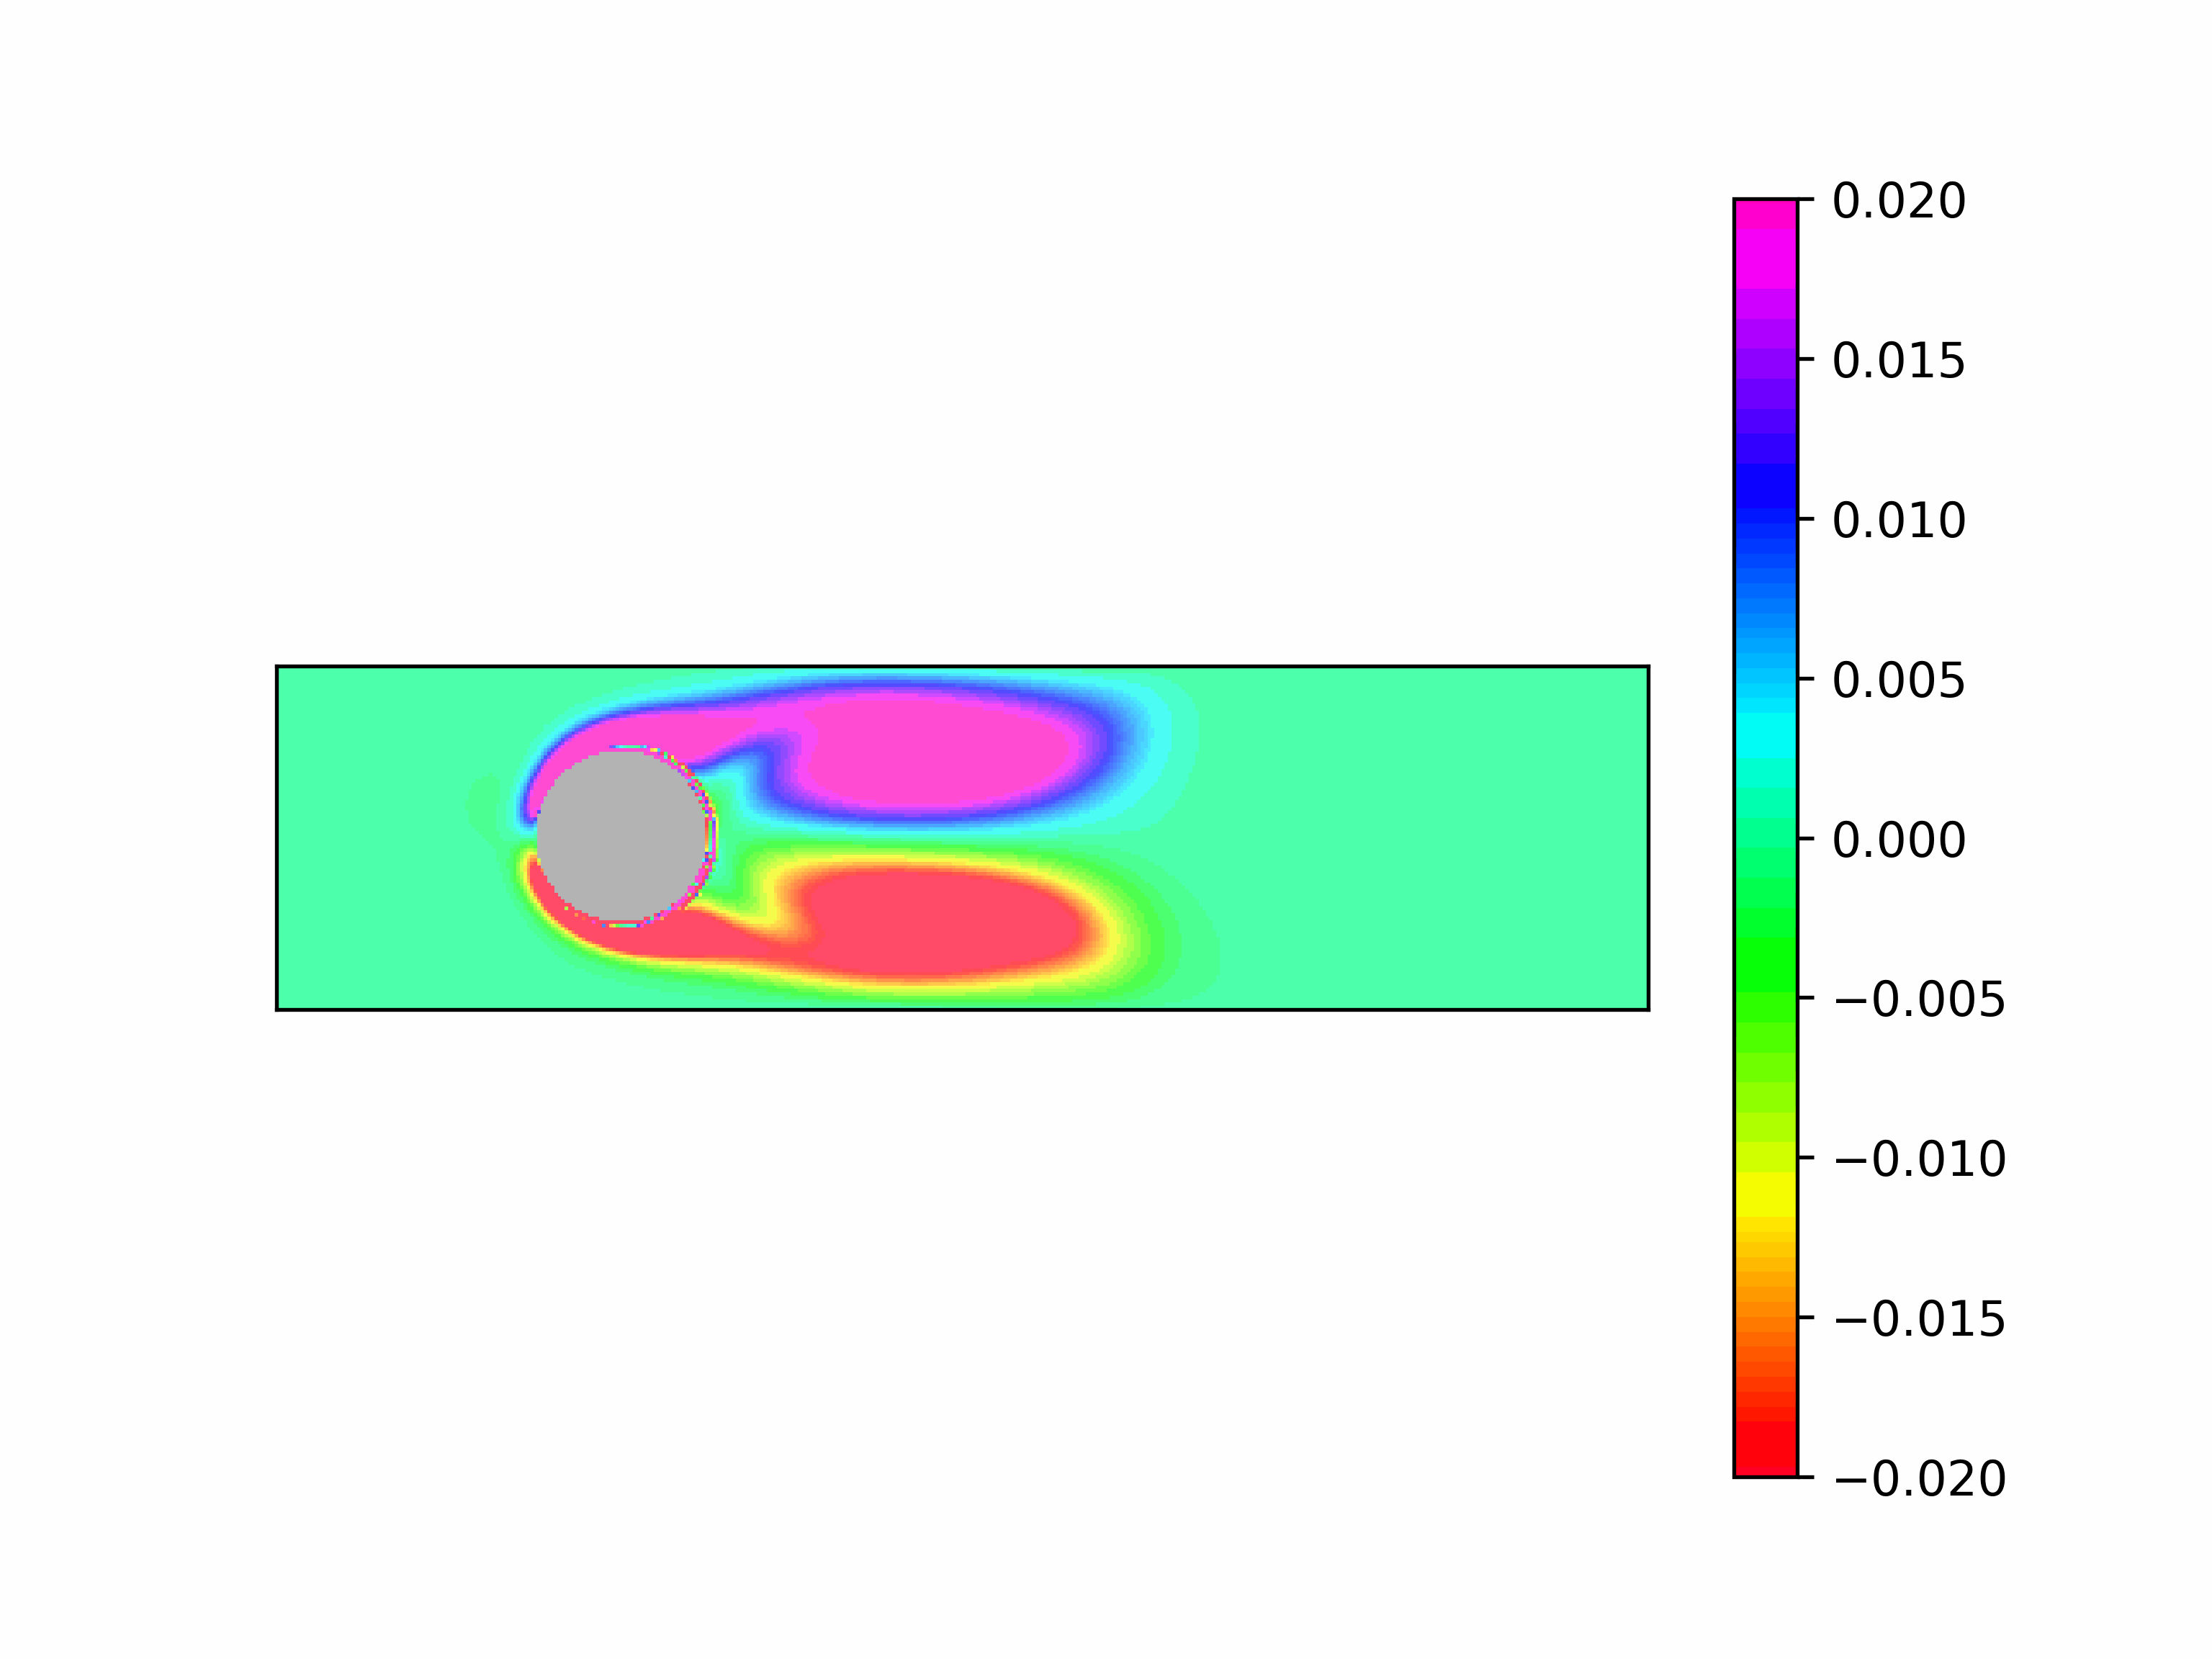

In [ ]:
from IPython.display import Image

# After the loop, create a GIF
gif_path = "animation.gif"  # Replace with your path
imageio.mimsave(gif_path, frames, duration=0.1, loop=0)

# Display the GIF in the notebook
display(Image(filename=gif_path))

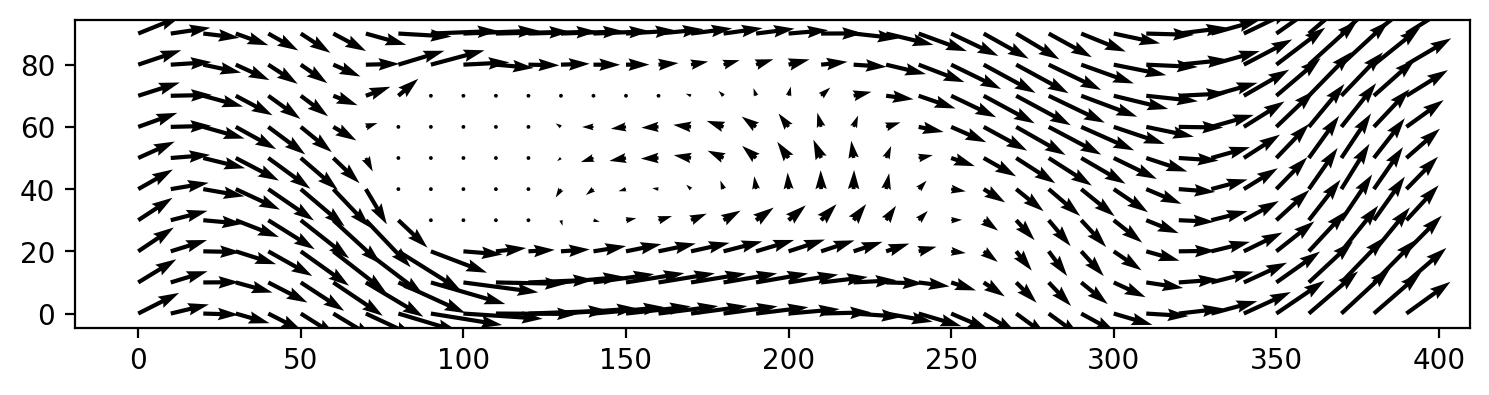

In [ ]:
fig = plt.figure(figsize=(9, 2), dpi=200)

plt.quiver(X[::10, ::10], Y[::10, ::10], ux[::10, ::10], uy[::10, ::10]);

https://drzgan.github.io/Python_CFD/26.LBM/26.%20LBM%20Poiseuille%20flow-2.html